# Task 2 — Spoken Arabic Digit, variable-length MFCC sequences
## 3.1 Data loading, collation, splits
* `Train_Arabic_Digit.txt`: 6,600 utterance blocks separated by blank lines = 10 digits x 660 blocks
  (66 speakers x 10 repetitions), stored digit by digit -> label = block_index // 660.
* `Test_Arabic_Digit.txt`: 2,200 blocks = 10 digits x 220 (22 other speakers) -> label = block_index // 220.
* Every line of a block is one 13-dimensional MFCC frame `x_t`.
* **Validation split is speaker-independent:** inside each digit the blocks are stored speaker by
  speaker (10 consecutive repetitions each), so the last 6 speakers' blocks (60 per digit) are held out.
  The official test file (22 unseen speakers) is the held-out test split.
* MFCC coefficients are standardised (z-score per coefficient) with statistics from the training split only.
* **Batch collation:** sequences are zero-padded to the longest utterance in the batch and the true
  lengths are carried along. Unidirectional models read the hidden state at index `len-1`; bidirectional
  models use `pack_padded_sequence`; attention masks padded frames. Padding therefore never influences a prediction.

train utterances=6600  test utterances=2200  feature dim=13
sequence length: min=4 max=93 mean=39.8
train padded X=(6000, 93, 13)  lengths 4-93  class counts=[600, 600, 600, 600, 600, 600, 600, 600, 600, 600]
val   padded X=(600, 62, 13)  lengths 14-62  class counts=[60, 60, 60, 60, 60, 60, 60, 60, 60, 60]
test  padded X=(2200, 83, 13)  lengths 7-83  class counts=[220, 220, 220, 220, 220, 220, 220, 220, 220, 220]


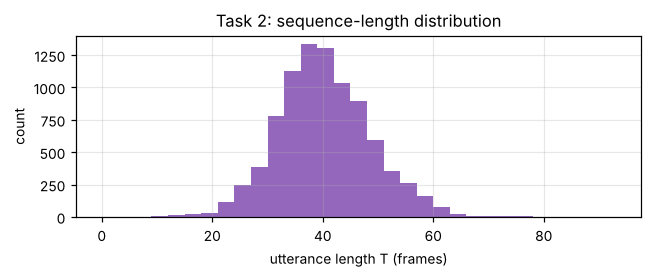

In [ ]:
def read_blocks(path):
    blocks, cur = [], []
    with open(path) as f:
        for line in f:
            v = line.split()
            if len(v) == 13: cur.append([float(t) for t in v])
            elif cur: blocks.append(np.array(cur, dtype=np.float32)); cur = []
    if cur: blocks.append(np.array(cur, dtype=np.float32))
    return blocks

A_train = read_blocks(os.path.join(DATA_DIR, 'Train_Arabic_Digit.txt'))
A_test = read_blocks(os.path.join(DATA_DIR, 'Test_Arabic_Digit.txt'))
ya_train = np.arange(len(A_train)) // 660; ya_test = np.arange(len(A_test)) // 220
lens = np.array([len(b) for b in A_train + A_test])
print(f'train utterances={len(A_train)}  test utterances={len(A_test)}  feature dim={A_train[0].shape[1]}')
print(f'sequence length: min={lens.min()} max={lens.max()} mean={lens.mean():.1f}')

within = np.arange(len(A_train)) % 660                    # position inside the digit's 660 blocks
a_tr_idx, a_va_idx = np.where(within < 600)[0], np.where(within >= 600)[0]   # 60 / 6 speakers
mu = np.concatenate([A_train[i] for i in a_tr_idx]).mean(0); sd = np.concatenate([A_train[i] for i in a_tr_idx]).std(0)

def collate(blocks, labels):
    """Zero-pad a list of (T_i, 13) arrays -> (N, T_max, 13) tensor + true lengths."""
    L = torch.tensor([len(b) for b in blocks]); X = torch.zeros(len(blocks), int(L.max()), 13)
    for i, b in enumerate(blocks): X[i, :len(b)] = torch.tensor((b - mu) / sd)
    return X, torch.tensor(labels, dtype=torch.long), L
S_tr = collate([A_train[i] for i in a_tr_idx], ya_train[a_tr_idx])
S_va = collate([A_train[i] for i in a_va_idx], ya_train[a_va_idx])
S_te = collate(A_test, ya_test)
for n, s in [('train', S_tr), ('val', S_va), ('test', S_te)]:
    print(f'{n:5s} padded X={tuple(s[0].shape)}  lengths {int(s[2].min())}-{int(s[2].max())}  class counts={np.bincount(s[1].numpy()).tolist()}')

fig, ax = plt.subplots(figsize=(6, 2.6)); ax.hist(lens, bins=range(0, 96, 3), color='tab:purple')
ax.set_xlabel('utterance length T (frames)'); ax.set_ylabel('count'); ax.set_title('Task 2: sequence-length distribution')
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/t2_lengths.png', dpi=150); plt.show()

## 3.2 Qualitative visualisation — MFCC heat-maps (coefficients x timesteps)
Three utterances (three different training speakers) for each of the 10 spoken digits.

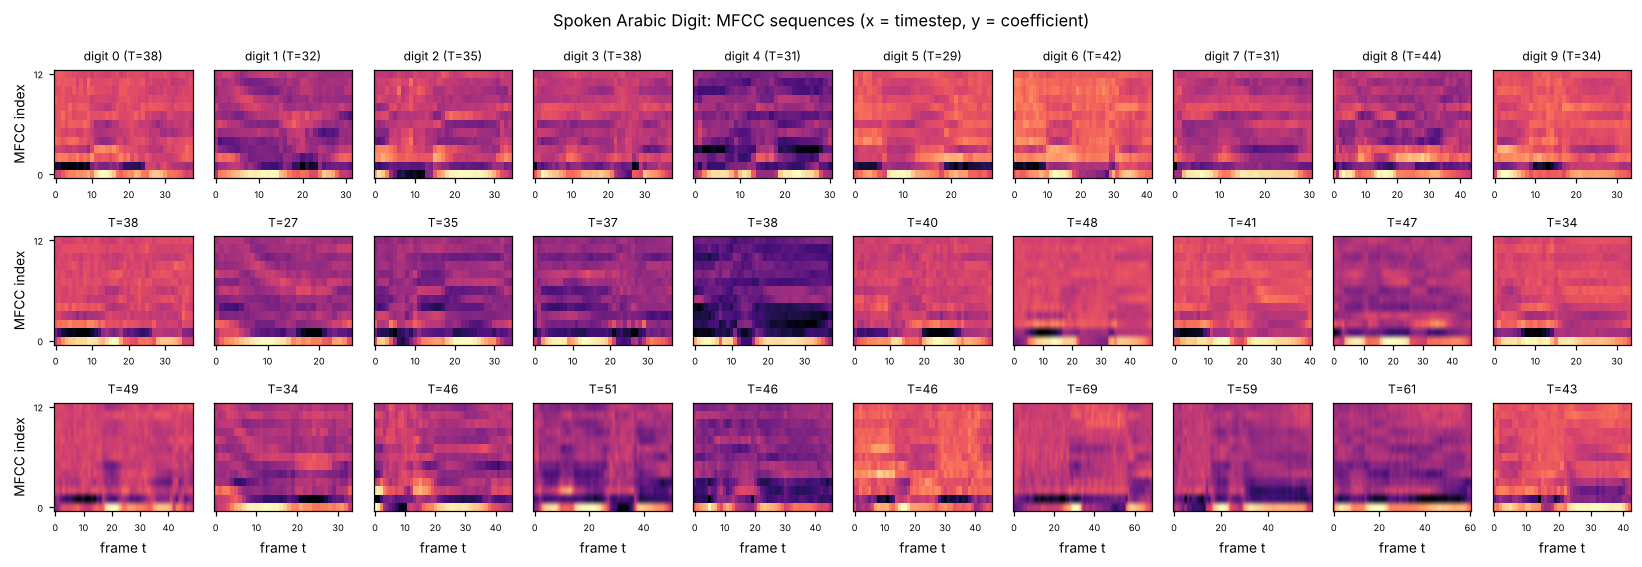

In [ ]:
fig, axes = plt.subplots(3, 10, figsize=(15, 5.2))
for d in range(10):
    for r, spk in enumerate([0, 25, 50]):
        b = A_train[d * 660 + spk * 10]; ax = axes[r, d]; ax.grid(False)
        im = ax.imshow(b.T, aspect='auto', origin='lower', cmap='magma')
        ax.set_title(f'digit {d} (T={len(b)})' if r == 0 else f'T={len(b)}', fontsize=8)
        ax.set_yticks([0, 12] if d == 0 else []); ax.tick_params(labelsize=6)
        if d == 0: ax.set_ylabel('MFCC index')
        if r == 2: ax.set_xlabel('frame t')
fig.suptitle('Spoken Arabic Digit: MFCC sequences (x = timestep, y = coefficient)')
fig.tight_layout(); fig.savefig(f'{FIG_DIR}/t2_mfcc.png', dpi=150); plt.show()

## 3.3 Hyperparameter search — RNN / LSTM / GRU (main grid)

In [ ]:
BS2 = 64
res2 = run_experiments(MAIN_GRID, 13, S_tr, S_va, S_te, BS2, 'T2')

[T2] RNN-L1-H64             params=   5706 epochs=40 conv=True  loss=0.46273 train= 82.55 val= 83.83 test= 76.41  (31s)


[T2] RNN-L1-H128            params=  19594 epochs=45 conv=True  loss=0.16699 train= 95.72 val= 95.67 test= 88.86  (50s)


[T2] RNN-L2-H64             params=  14026 epochs=44 conv=True  loss=0.20439 train= 94.58 val= 91.00 test= 85.59  (63s)


[T2] RNN-L2-H128            params=  52618 epochs=39 conv=True  loss=0.10349 train= 97.33 val= 92.83 test= 90.18  (92s)


[T2] LSTM-L1-H64            params=  20874 epochs=37 conv=True  loss=0.03924 train= 99.28 val= 97.50 test= 92.86  (31s)


...

[T2] LSTM-L2-H128           params= 206602 epochs=22 conv=True  loss=0.00376 train= 99.95 val= 98.00 test= 94.50  (125s)


[T2] GRU-L1-H64             params=  15818 epochs=38 conv=True  loss=0.05229 train= 98.98 val= 99.00 test= 94.05  (72s)


[T2] GRU-L1-H128            params=  56202 epochs=34 conv=True  loss=0.01573 train= 99.75 val= 98.83 test= 94.82  (111s)


[T2] GRU-L2-H64             params=  40778 epochs=31 conv=True  loss=0.01532 train= 99.78 val= 98.50 test= 93.86  (128s)


[T2] GRU-L2-H128            params= 155274 epochs=27 conv=True  loss=0.00488 train= 99.95 val= 98.83 test= 95.27  (193s)


## 3.4 Bonus — bidirectional networks and temporal attention pooling

In [ ]:
res2.update(run_experiments(BONUS_GRID, 13, S_tr, S_va, S_te, BS2, 'T2-bonus'))

[T2-bonus] BiLSTM-L1-H128         params= 149002 epochs=20 conv=True  loss=0.00328 train= 99.98 val= 95.83 test= 96.95  (268s)


[T2-bonus] BiGRU-L1-H128          params= 112394 epochs=23 conv=True  loss=0.00385 train= 99.97 val= 98.50 test= 96.73  (259s)


[T2-bonus] LSTM-L1-H128+Att       params=  91146 epochs=16 conv=True  loss=0.02637 train= 99.47 val= 96.33 test= 95.32  (35s)


[T2-bonus] GRU-L1-H128+Att        params=  72842 epochs=25 conv=True  loss=0.01726 train= 99.68 val= 97.33 test= 96.68  (94s)


[T2-bonus] BiGRU-L2-H128+Att      params= 474890 epochs=16 conv=True  loss=0.00151 train=100.00 val= 99.33 test= 97.95  (436s)


## 3.5 Average training error vs. epochs for every hyperparameter set

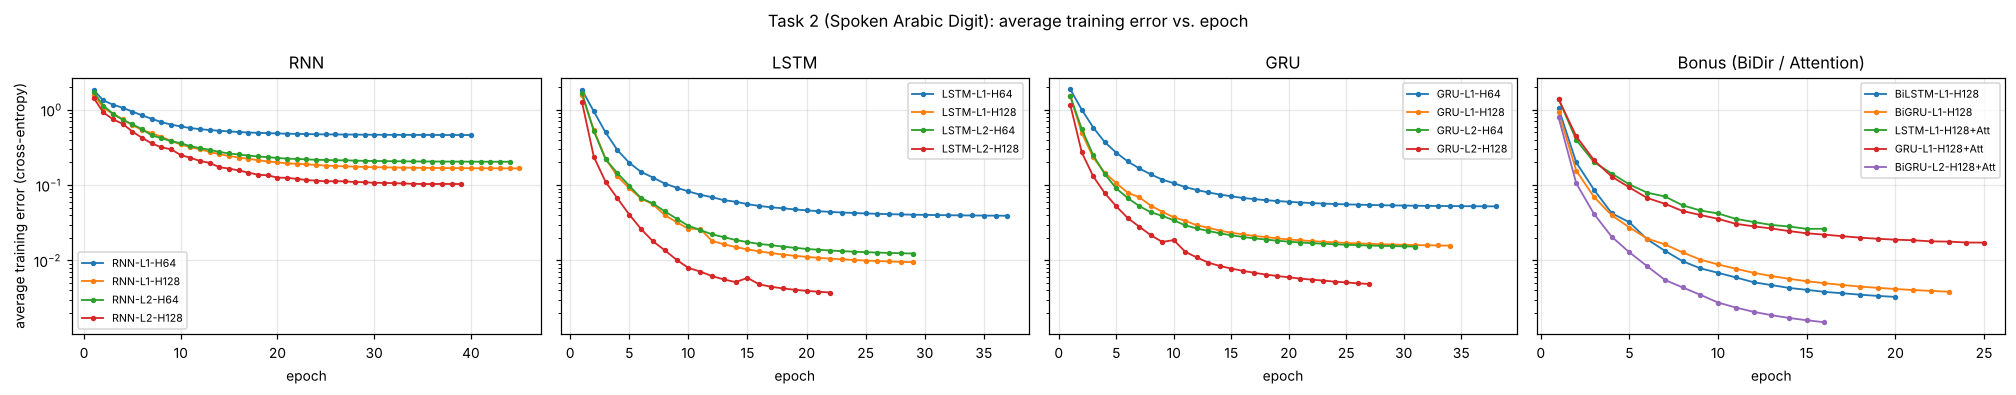

In [ ]:
plot_loss_curves(res2, 'Task 2 (Spoken Arabic Digit): average training error vs. epoch', 't2_loss.png', groups_of(res2))

## 3.6 Summary table

,Model,Cell,Layers,Hidden,BiDir,Attention,Params,Epochs,Converged,FinalTrainLoss,TrainAcc,ValAcc,TestAcc,TimeSec
0,RNN-L1-H64,RNN,1,64,False,False,5706,40,True,0.46273,82.55,83.83,76.41,31
1,RNN-L1-H128,RNN,1,128,False,False,19594,45,True,0.16699,95.72,95.67,88.86,50
2,RNN-L2-H64,RNN,2,64,False,False,14026,44,True,0.20439,94.58,91.00,85.59,63
3,RNN-L2-H128,RNN,2,128,False,False,52618,39,True,0.10349,97.33,92.83,90.18,92
4,LSTM-L1-H64,LSTM,1,64,False,False,20874,37,True,0.03924,99.28,97.50,92.86,31
5,LSTM-L1-H128,LSTM,1,128,False,False,74506,29,True,0.00950,99.88,98.00,94.27,54
6,LSTM-L2-H64,LSTM,2,64,False,False,54154,29,True,0.01237,99.92,98.17,94.64,46
7,LSTM-L2-H128,LSTM,2,128,False,False,206602,22,True,0.00376,99.95,98.00,94.50,125
8,GRU-L1-H64,GRU,1,64,False,False,15818,38,True,0.05229,98.98,99.00,94.05,72
9,GRU-L1-H128,GRU,1,128,False,False,56202,34,True,0.01573,99.75,98.83,94.82,111


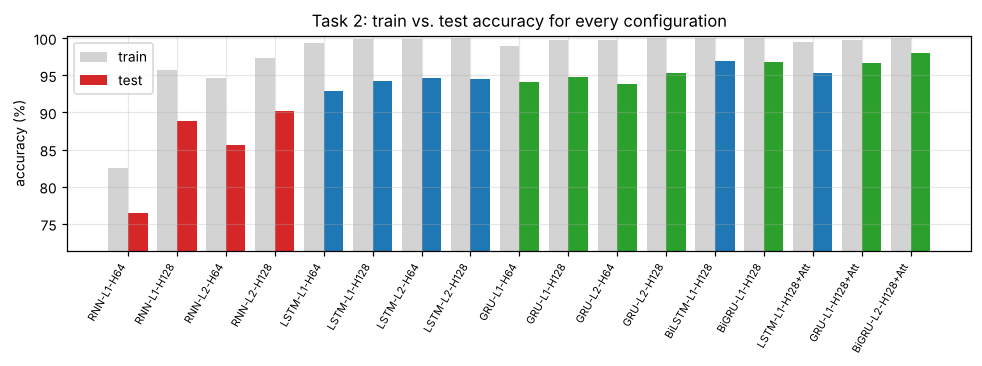

In [ ]:
df2 = summary_table(res2); df2.to_csv(f'{OUT_DIR}/task2_summary.csv', index=False)
display(df2)
plot_acc_bars(df2, 'Task 2: train vs. test accuracy for every configuration', 't2_acc.png')

## 3.7 Best models and confusion matrices

Best plain RNN : RNN-L1-H128      train=95.72%  val=95.67%  test=88.86%
Best plain LSTM: LSTM-L2-H64      train=99.92%  val=98.17%  test=94.64%
Best plain GRU : GRU-L1-H64       train=98.98%  val=99.00%  test=94.05%

BEST OVERALL (Task 2): BiGRU-L2-H128+Att
  final training accuracy = 100.00%
  validation accuracy     = 99.33%
  test accuracy           = 97.95%

              precision    recall  f1-score   support

           0     0.9459    0.9545    0.9502       220
           1     0.9955    1.0000    0.9977       220
           2     0.9955    0.9955    0.9955       220
           3     0.9636    0.9636    0.9636       220
           4     0.9690    0.9955    0.9821       220
           5     0.9954    0.9909    0.9932       220
           6     0.9952    0.9409    0.9673       220
           7     0.9769    0.9591    0.9679       220
           8     0.9865    0.9955    0.9910       220
           9     0.9735    1.0000    0.9865       220

    accuracy                         0.

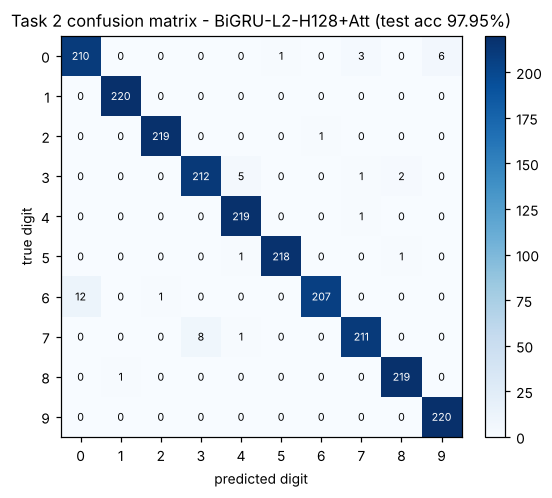

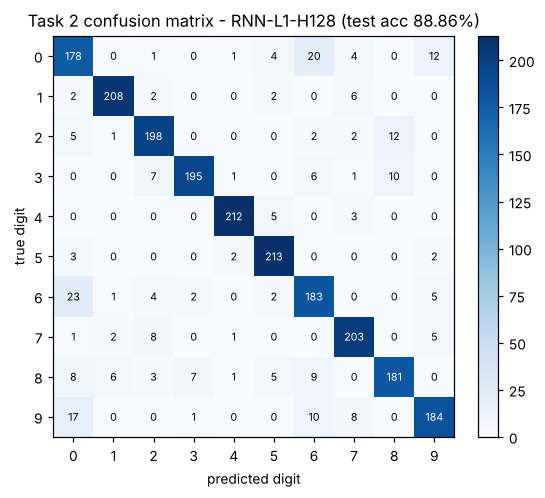

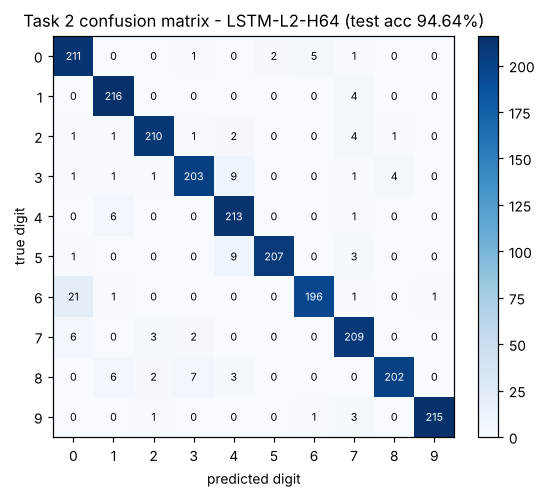

In [ ]:
best2, cms2 = report_best(res2, ya_test, 'Task 2', 't2')

## 3.8 Gradient flow on long utterances
Same measurement as in Task 1, restricted to test utterances with at least 40 frames and aligned at the
end of each utterance (0 = last frame, -39 = 39 steps before the read-out).

utterances used: 256


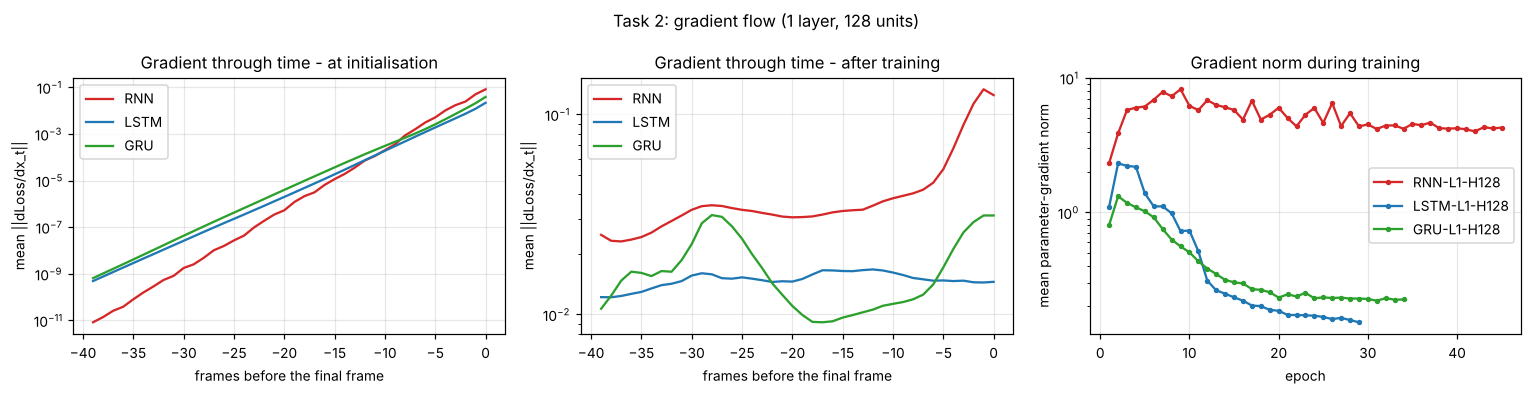

RNN  ratio earliest/latest gradient:  init=1.014e-10   trained=2.002e-01
LSTM ratio earliest/latest gradient:  init=2.262e-08   trained=8.384e-01
GRU  ratio earliest/latest gradient:  init=1.691e-08   trained=3.417e-01


In [ ]:
long = torch.where(S_te[2] >= 40)[0][:256]
S_long = (S_te[0][long], S_te[1][long], S_te[2][long]); print('utterances used:', len(long))
flow2 = gradient_flow_figure(res2, 13, S_long, 'Task 2: gradient flow (1 layer, 128 units)', 't2_gradflow.png',
                             last_k=40, xlabel='frames before the final frame')

## 4. Cross-task comparison of the three recurrent cells

In [ ]:
rows = []
for task, df in [('Task 1', df1), ('Task 2', df2)]:
    m = df[~df.BiDir & ~df.Attention]
    for cell in ['RNN', 'LSTM', 'GRU']:
        s = m[m.Cell == cell]
        rows.append(dict(Task=task, Cell=cell, MeanTrainAcc=round(s.TrainAcc.mean(), 2), MeanTestAcc=round(s.TestAcc.mean(), 2),
                         BestTestAcc=s.TestAcc.max(), WorstTestAcc=s.TestAcc.min(), MeanEpochs=round(s.Epochs.mean(), 1),
                         MeanSecPerEpoch=round((s.TimeSec / s.Epochs).mean(), 1)))
cmp_df = pd.DataFrame(rows); cmp_df.to_csv(f'{OUT_DIR}/cell_comparison.csv', index=False); display(cmp_df)

,Task,Cell,MeanTrainAcc,MeanTestAcc,BestTestAcc,WorstTestAcc,MeanEpochs,MeanSecPerEpoch
0,Task 1,RNN,98.77,93.25,95.92,91.20,30.8,4.3
1,Task 1,LSTM,99.70,95.44,96.23,94.80,29.2,9.5
2,Task 1,GRU,99.49,94.98,96.00,93.87,28.5,12.4
3,Task 2,RNN,92.54,85.26,90.18,76.41,42.0,1.4
4,Task 2,LSTM,99.76,94.07,94.64,92.86,29.2,2.5
5,Task 2,GRU,99.62,94.50,95.27,93.86,32.5,4.1


In [ ]:
# Save everything the report needs
dump = dict(settings=dict(TOL=TOL, MAX_EPOCHS=MAX_EPOCHS, LR=LR, LR_GAMMA=LR_GAMMA, CLIP=CLIP, BS1=BS1, BS2=BS2),
            best1=best1, best2=best2, dig_acc=dig_acc, flow1=flow1, flow2=flow2,
            cm1={k: v.tolist() for k, v in cms1.items()}, cm2={k: v.tolist() for k, v in cms2.items()},
            hist1={n: r['hist'] for n, r in res1.items()}, hist2={n: r['hist'] for n, r in res2.items()},
            splits=dict(t1=[len(K_tr[0]), len(K_va[0]), len(K_te[0])], t2=[len(S_tr[0]), len(S_va[0]), len(S_te[0])]))
json.dump(dump, open(f'{OUT_DIR}/results.json', 'w'))
print('saved', os.listdir(OUT_DIR))

saved ['task2_summary.csv', 'cell_comparison.csv', 'results.json', 'progress.log', 'task1_summary.csv']


## 5. Observations
The detailed comparative analysis (performance, convergence behaviour and gradient flow of
Vanilla RNN vs LSTM vs GRU, plus the bonus experiments) is written up in `report.pdf`, using
exactly the tables and figures produced above.